Now that we've become familiar with the construction, implementation, theory, results and inferences of quantum circuits, it's time to explore some of the most topic-significant quantum algorithms that harness the power of quantum computing to solve real problems in quantum physics and chemistry. 

**Quantum Algorithms** are one of the most important and exciting areas of research in quantum computing, and more are being developed day by day. They leverage the principles of quantum mechanics to solve problems more efficiently than classical algorithms, often with polynomial, superpolynomial, or even exponential speedups. 

This is quite a hefty notebook, so feel free to take your time going through it. The end of one algorithm is not the beginning of the next; take breaks at checkpoints that make sense to you.

Unlike traditional coursework on quantum algorithms, I'd like to take a different approach here. I'll gradually introduce you to some key concepts that underpin these algorithms, and then walk you through those algorithms that are specifically useful for applications in physics and chemistry. I'll largely ignore query-based algorithms for sorting/picking data that you probably have heard of before, like Grover's and Shor's algorithms.

Feel free to use the links to jump to specific sections:

1. [Quantum Phase Estimation](#quantum-phase-estimation)
2. [The Variational Quantum Eigensolver](#the-variational-quantum-eigensolver)
3. [Trotterization](#trotterization)
4. [The Quantum Approximate Optimization Algorithm](#the-quantum-approximate-optimization-algorithm)

In [98]:
import numpy as np, matplotlib.pyplot as plt
plt.style.use(['science', 'notebook', 'grid', 'dark_background'])
from scipy.optimize import minimize
from time import time

# OTHER QISKIT IMPORTS

from qiskit import *
from qiskit.visualization import *
from qiskit.circuit.library import *
from qiskit.primitives import StatevectorEstimator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit_aer import *
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.synthesis import LieTrotter, SuzukiTrotter

# DRAW STYLE (default mpl dark), check https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits and 
# https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.circuit_drawer for more styles

def draw_circuit(qc):
    return qc.draw(output = 'mpl', style = 'iqp-dark')

***

# Intro - Clearing up the Jargon

All those topics might've stirred up a storm of questions in your mind. Before we dive into the algorithms themselves, let's clarify some of prerequisites that will be used throughout this section. First of all, quantum algorithms aren't a magical solution to all computational problems (formally called *undecidable problems*). They're designed to leverage Quantum Supremacy to solve specific types of problems more efficiently than classical algorithms.

You're also probably wondering about sub-polynomial, polynomial, superpolynomial, and exponential speedups. These terms refer to how the *time complexity* of an algorithm scales with the size of the input data. They're associated with the concept of `Big O notation`, which is used to describe the upper bound or 'worst case' of an algorithm's growth rate. Here's a brief overview:

Time complexity is commonly estimated by counting the number of elementary operations performed by the algorithm, supposing that each elementary operation takes a fixed amount of time to perform. If $n$ is the size of the input, then $O(f(n))$ describes the upper bound of the complexity. Based on some common growth functions, $f$ can take on polynomial-esque $O(n^k)$ forms, exponential $O(c^n)$ forms etc., where $k$ defines the degree of the polynomial and $c>1$.

Formally defined, the *Ordnung* $O$ of a function $f(n)$ is the set of functions $g(n)$ such that there exist positive constants $n_0$ and $c$ such that 

$$f(n) \leq cg(n)\hspace{0.2cm}\forall\hspace{0.2cm}n \geq n_0$$

where $n_0$ is the point from which the upper bound holds true, $c$ is a constant multiplier that scales the function $g(n)$ to ensure it bounds $f(n)$ from above.

One last thing - the speedups that quantum algorithms provide are often probabilistic in nature, and they may not always guarantee a correct solution. Instead, they often provide a high probability of correctness, which can be amplified through repeated runs of the algorithm.

# Primer: The Quantum Fourier Transform

Why is this here? Well, many quantum algorithms, including Quantum Phase Estimation (QPE) and Shor's algorithm, rely on the *Quantum Fourier Transform* (QFT) as a fundamental building block. The QFT is the quantum analogue of the classical discrete Fourier transform (DFT) which you might've learned if you have a background in signal processing or applied mathematics.

The QFT acts on a quantum register of qubits and transforms the amplitudes of the quantum state into a **new basis,** so that comes to $2^n$ amplitudes for an $n$-qubit system, with a typical $O(n^2)$ complexity for its implementation. This is exponentially faster than the classical DFT, which has a time complexity of $O(n2^n)$. In the end, both act on tuples of complex numbers, but in the quantum case they can represent probability amplitudes of measurement.

For the uninitiated, let's build up the QFT from the classical DFT. Say you have a tuple $(x_0, x_1, \ldots, x_{N-1})\in\mathbb{C}^N$. The DFT transforms this tuple into another $(y_0, y_1, \ldots, y_{N-1})$ according to the mapping $$y_k = \frac{1}{\sqrt{N}}\sum_{j=0}^{N-1} x_j\omega^{-jk} \quad \text{for } k = 0, 1, \ldots, N-1$$

where $\omega = \exp\bigg(\dfrac{2\pi i}{N}\bigg)$ is a primitive $N^{\text{th}}$ root of unity. The DFT has a dual or inverse transform, and conventionally the QFT is equivalent to the **inverse DFT,** defined as $$x_j = \frac{1}{\sqrt{N}}\sum_{k=0}^{N-1} y_k\omega^{jk} \quad \text{for } j = 0, 1, \ldots, N-1$$

Now transitioning 
- $\ket{x}=\sum\limits_{j=0}^{N-1} x_j\ket{j}$, 
- $\ket{y}=\sum\limits_{k=0}^{N-1} y_k\ket{k}$, 

and $N=2^n$, we can express the QFT and its dual as the maps $$\begin{align*}\ket{y} = \mathscr{\hat F}\ket{x} = \frac{1}{\sqrt{2^n}}\sum_{j=0}^{2^n-1}\sum_{k=0}^{2^n-1} x_j\omega^{jk}\ket{k}&&&\longleftrightarrow&&&\ket{x} = \mathscr{\hat F}^{\dagger}\ket{y} = \frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1}\sum_{j=0}^{2^n-1} y_k\omega^{-jk}\ket{j}\end{align*}$$

Think of these like rotations in a high-dimensional complex vector space, where the basis states $\ket{j}$ and $\ket{k}$ represent different configurations of qubits. The QFT essentially re-expresses the quantum state in terms of these new basis states, which can be particularly useful for certain quantum algorithms that exploit periodicity or frequency information.

Equivalently, the QFT can be represented as a unitary operator $\hat{\mathscr F}$ of size $2^n \times 2^n$ of elements $$\mathscr F_{jk} = \frac{1}{\sqrt{2^n}}\omega^{jk} \quad \text{for } j, k = 0, 1, \ldots, 2^n-1$$ The inverse QFT is just $\mathscr F^{\dagger}$. Try this on paper, $\mathscr F \mathscr F^{\dagger} = I$. What's your inference? Can a QFT circuit be reversed to get back the original state?

> **Note:** The QFT can be viewed as a **generalization** of the Hadamard transform to multiple qubits, where the Hadamard transform creates superpositions of basis states. The QFT not only creates superpositions but also introduces specific phase relationships between the basis states, which is crucial for many quantum algorithms. See for yourself - try to obtain the Hadamard transform using the QFT on $n$ qubits initialized to $\ket{0}^{\otimes n}$:
>
> $$\hat{\mathscr F}\ket{0^n} = \frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1} \omega^{0\cdot k}\ket{k} = \frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1} \ket{k}\equiv \hat H^{\otimes n}$$
>
> No problemo!


We can generalize the QFT for a state $\ket{x}=\ket{x_0x_1\ldots x_{n-1}}$ as follows:

$$\hat{\mathscr F}\ket{x} = \frac{1}{\sqrt{2^n}}\bigotimes_{j=1}^{n} \left(\ket{0}+e^{2\pi ix/2^j}\ket{1}\right)=\frac 1{2^{1/2}}\left(\ket{0}+e^{2\pi ix/2}\ket{1}\right)\otimes\frac 1{2^{1/2}}\left(\ket{0}+e^{2\pi ix/2^2}\ket{1}\right)\otimes \cdots \otimes \frac 1{2^{1/2}}\left(\ket{0}+e^{2\pi ix/2^n}\ket{1}\right)$$

where $\bigotimes$ denotes the Kronecker product series. This is wildly complicated to prove from our formula above, but hopefully you can see what I'm trying to convey here. The QFT can be split into a series of tensor products, each corresponding to a qubit in the quantum register. Each term in the tensor product represents a superposition of the basis states $\ket{0}$ and $\ket{1}$, with a phase factor that depends on the value of $x$ and the position of the qubit. 

Let's try it out in Qiskit! Here's a simple implementation of the QFT for a 3-qubit system:

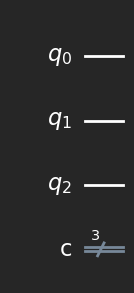

In [3]:
qc = QuantumCircuit(3, 3)

draw_circuit(qc)

We use our generalized QFT formula to construct the circuit. As you can see, the QFT circuit consists of a series of **Hadamard gates** and **controlled phase rotation gates.** The Hadamard gate creates superpositions, while the controlled phase rotations introduce the necessary phase relationships between the qubits. 

Think of it this way - after we Hadamard each qubit, we apply controlled phase rotations (remember, we only have to rotate the $\ket{1}$ components of each state) to entangle the qubits and encode the frequency information into the quantum state. The phase angle is sure enough, $\theta = 2\pi/2^j$ for each qubit $j$. We use the 'Hadamarded' qubits as controls for the controlled phase rotations on the targets.

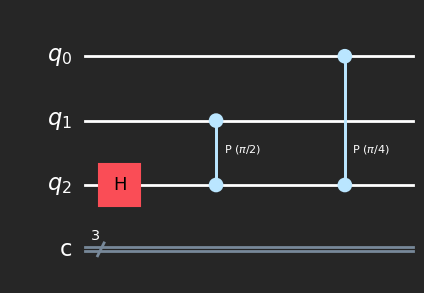

In [4]:
qc.h(2)
qc.cp(np.pi / 2, 1, 2) # CROT from qubit 1 to qubit 2 with angle pi/2
qc.cp(np.pi / 4, 0, 2) # CROT from qubit 0 to qubit 2 with angle pi/4

draw_circuit(qc)

Onto qubit 2 (technically one, cause qiskit starts counting from 0):

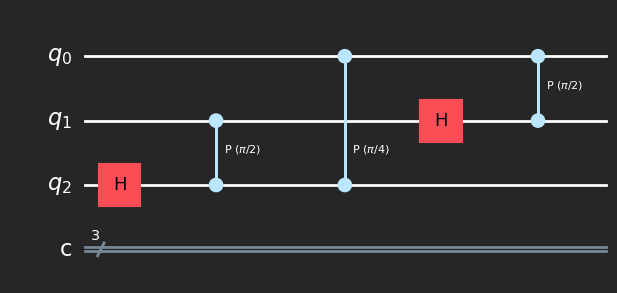

In [5]:
qc.h(1)
qc.cp(np.pi / 2, 0, 1) # CROT from qubit 0 to qubit 1 with angle pi/2

draw_circuit(qc)

And qubit 3 is easy, as there are no more qubits to control it!

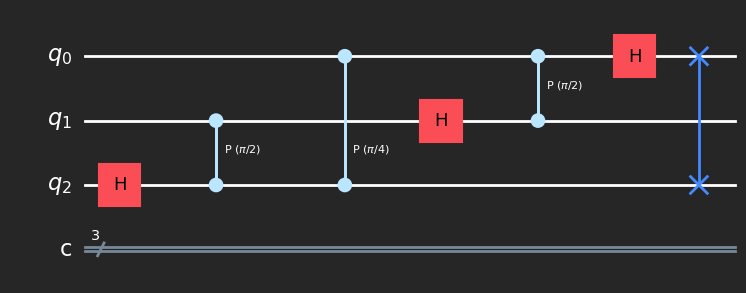

In [6]:
qc.h(0)
qc.swap(0, 2)
draw_circuit(qc)

That's all there is! I'm sure y'all can do a four- or five-qubit QFT on your own now. Just remember the pattern of Hadamard and controlled phase rotations, and you'll be good to go! Now do remember to swap the qubits at the end to reverse their order, since the QFT outputs the qubits in reverse order compared to their input. 

Also remember, feeding in a qubit named in decimal to be QFT'd requires a binary representation of the integer you want to encode. For example, to encode the integer 5 in a 3-qubit system, you'd represent it as $\ket{101}$, so do remember to convert your integers to binary strings of appropriate length before initializing your quantum states for the QFT.

You can initialize such a state with the help of a helper function. Take a look at a 5-qubit QFT, and try to QFT any integer between 0 and 31! I've implemented a binary converter for you to help with that.

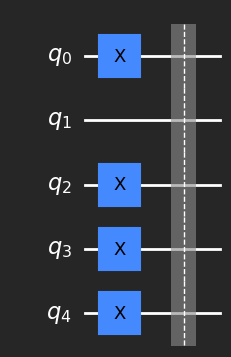

In [7]:
template = QuantumCircuit(5)

def initialize_integer(qc, integer, n_qubits):
    binary_str = format(integer, f'0{n_qubits}b')
    
    for idx, bit in enumerate(reversed(binary_str)):
        
        if bit == '1':
            qc.x(idx)
    
    qc.barrier()
    
    return qc

initialize_integer(template, 29, 5)  # Enter any integer expressable in 5 bits (~ 0-31)
draw_circuit(template)

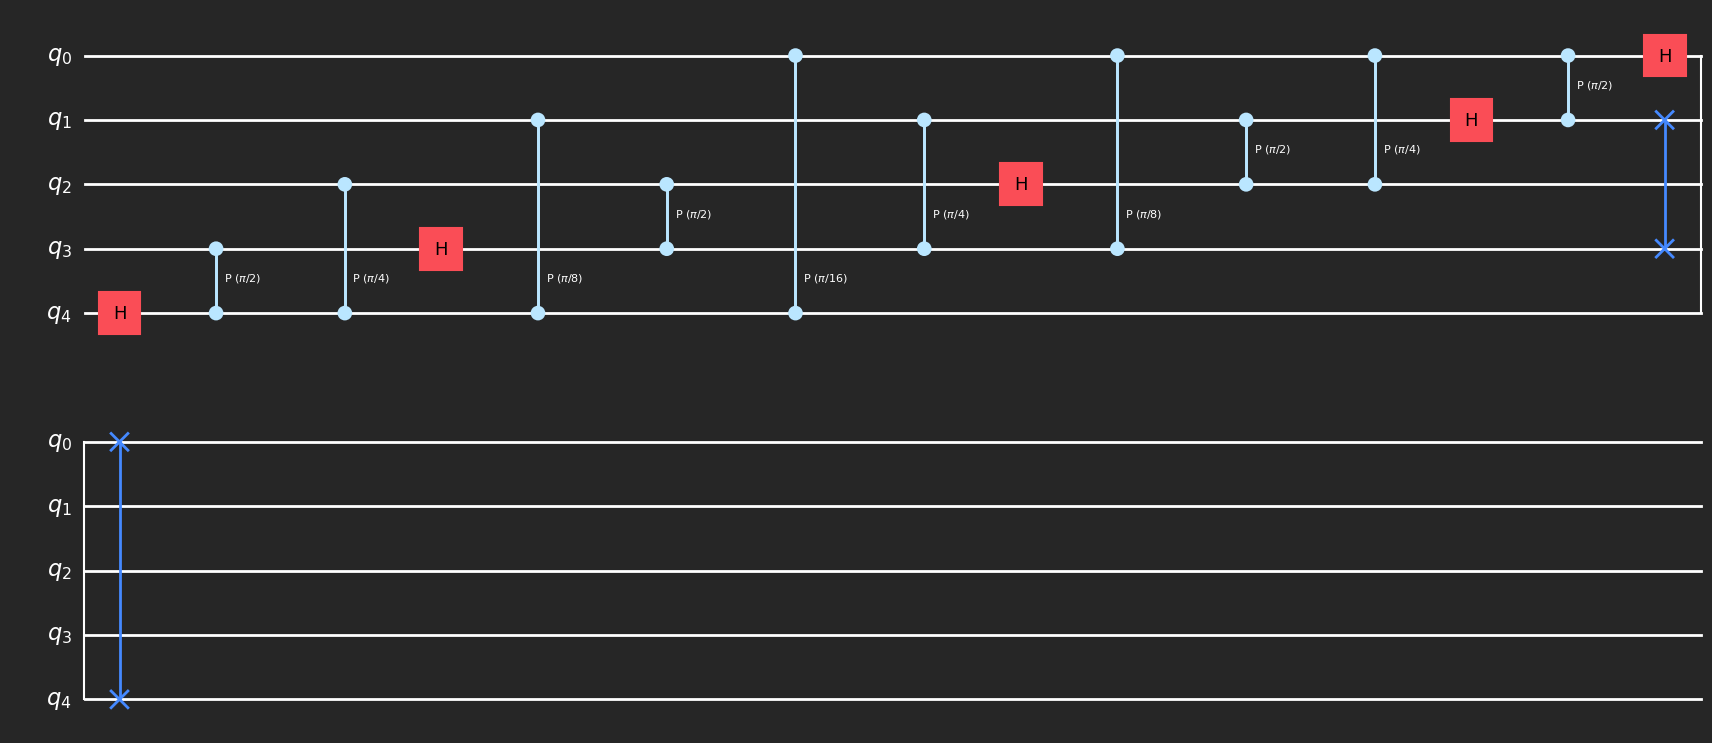

In [8]:
qft = QuantumCircuit(5)

qft.h(4)
qft.cp(np.pi / 2, 3, 4)
qft.cp(np.pi / 4, 2, 4)
qft.cp(np.pi / 8, 1, 4)
qft.cp(np.pi / 16, 0, 4)

qft.h(3)
qft.cp(np.pi / 2, 2, 3)
qft.cp(np.pi / 4, 1, 3)
qft.cp(np.pi / 8, 0, 3)

qft.h(2)
qft.cp(np.pi / 2, 1, 2)
qft.cp(np.pi / 4, 0, 2)

qft.h(1)
qft.cp(np.pi / 2, 0, 1)

qft.h(0)
qft.swap(0, 4)
qft.swap(1, 3)

draw_circuit(qft)

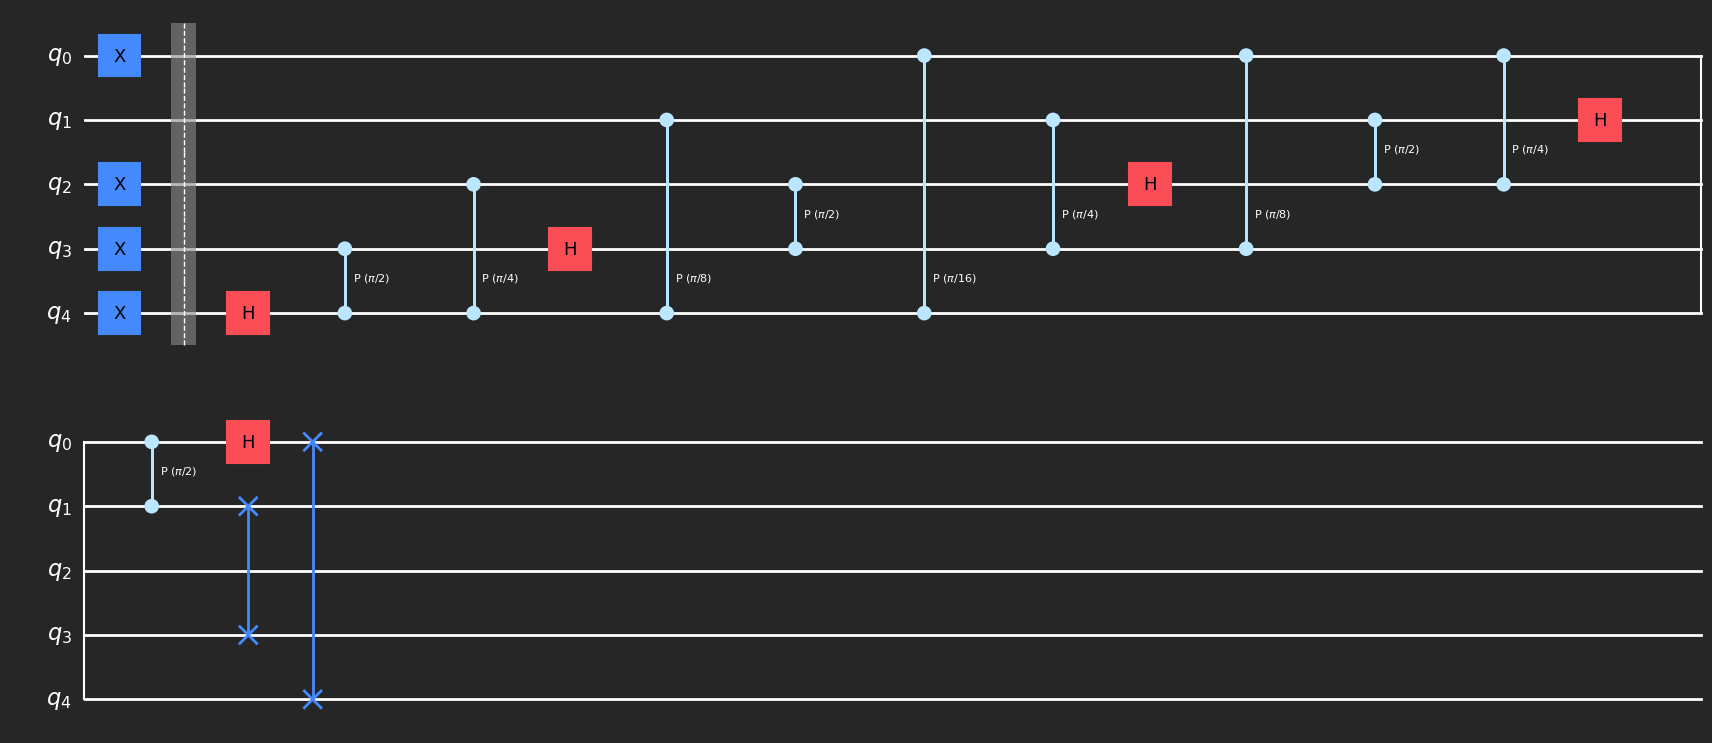

In [9]:
qft.compose(template, inplace = True, front = True)
draw_circuit(qft)

Now let's see the rotations we made. We expect for qubits 0 through 4 to have rotations of $\pi/2$, $\pi/4$, $\pi/8$, and $\pi/16$ from the conventional vertical $\ket{0}$ respectively. 

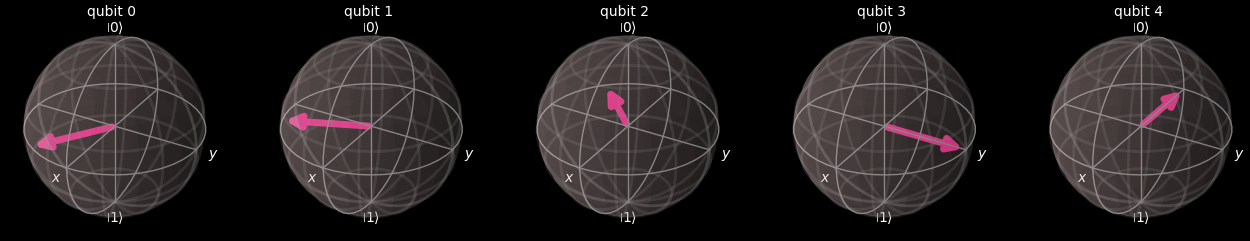

In [10]:
plot_bloch_multivector(qft)

What's important to note here is all orientations are **equatorial,** which is expected behavior from the QFT. Phase angle notably decreases exponentially with increasing qubit index.

***

# 1. Quantum Phase Estimation

Now we're talking! *Quantum Phase Estimation* (QPE) is a cornerstone quantum algorithm that estimates the phase (or eigenvalue) associated with an eigenvector of a unitary operator. Needless to say, it's a fundamental building block for many other quantum algorithms, including Shor's algorithm for factoring large integers and algorithms for solving linear systems of equations. We won't be covering those here, but QPE is also crucial for quantum simulations in chemistry and physics, where it can be used to estimate energy eigenvalues of quantum systems.

## A Hefty Introduction:

For the unitiated, let's recap or introduce you to phase in general:

Phase, commonly symbolized by the Greek letters $\varphi$ or $\delta$, is a fundamental quantity in wave and quantum mechanics, that describes the position of a point within a wave cycle or oscillation, say of a matter wave or electromagnetic wave. This position is expressed as an angle, that which when measured against a full rotation/cycle of $2\pi$ radians, a fraction of the traversed cycle. Formally defined, for a time-varying function $F(t)$ with period $T$ such that $F(t) = F(t + T)$, the phase $\varphi$ at time $t$ can be expressed as $$\varphi(t)=2\pi\bigg[\bigg[\frac{t-t_0}{T}\bigg]\bigg]$$ 
where $[[\cdot]]=(\cdot)-\lfloor\cdot\rfloor$ denotes the fractional part.

Transitioning fluidly to quantum mechanics, where 'waves' are just probability distributions, phase plays a crucial role in determining the behavior of quantum systems. In quantum mechanics, phase differences between components of a wavefunction or multiple interacting or interdependent wavefunctions can lead to interference effects, which are central to many quantum phenomena. 

Multiplication by a complex *phase factor* $e^{i\varphi}$ alters the phase of the wavefunction without changing its probability distributio, assuming a complex can be written in polar form as $re^{i\varphi}$, where $r$ is the magnitude and $\varphi$ is the phase angle. See for yourselves, for the wavefunction $\psi(x) = Ae^{i(kx - \omega t)}$, multiplying by a phase factor $e^{i\varphi}$ yields

$$e^{i\varphi} \psi(x) = Ae^{i(kx - \omega t + \varphi)}$$

In this particular context, we use the phase to describe the **eigenvalue of a unitary operator** $\hat U$ associated with an eigenvector $\ket{\psi}$. If $\ket{\psi}$ is an eigenvector of $\hat U$, then applying $\hat U$ to $\ket{\psi}$ results in a **phase shift:**

There's also relative and global phase, commonly used terms in QPE. A *global phase* is a uniform phase factor that multiplies the entire wavefunction or quantum state, and it has no observable consequences in quantum mechanics. In contrast, a *relative phase* refers to the phase difference between two or more components of a superposition state, and it can have significant physical implications, affecting interference patterns and measurement outcomes.

Time-evolution operators $\hat U(t,t_0)$ are unitary operators that describe how quantum states evolve over time. If $\ket{\psi(t)}$ is an eigenstate of the Hamiltonian $\hat H$ with eigenvalue $E$, then applying the time-evolution operator results in a **phase shift** (which is currently unknown) which we assume is proportional to the energy eigenvalue and time. 

Solving the time-dependent Schrödinger equation for a state $\ket{\psi(t)}=\hat U \ket{\psi(t_0)}$ yields the expression $$i\hbar \frac{\partial}{\partial t} \ket{\psi(t)} = \hat{H}\ket{\psi(t)}\implies\hat U(t, t_0) \ket{\psi(t_0)} = e^{-iE(t-t_0)/\hbar} \ket{\psi(t_0)}$$ assuming a time-independent Hamiltonian. Try it out on paper!

Now, the phase $\varphi$ acquired by the eigenstate $\ket{\psi}$ after time $t-t_0$ is hence $$\varphi = -\frac{E(t-t_0)}{\hbar}$$

## Finally, a Look at the Algorithm

The result makes it clear that QPE is a phase microscope, which can be used to measure the phase $\varphi$ associated with an eigenvector $\ket{\psi}$ of a unitary operator $\hat U$. Take two quantum registers of multiplicities $m$ and $n$ respectively. The first register, initialized to $\ket{0}^{\otimes m}$, is used to store the estimated phase, while the second register, initialized to the eigenstate $\ket{\psi}$, is used to apply controlled unitary operations. The unitary $\hat U$ is applied in a controlled manner, with $n$ as controls and $m$ as targets.

As the eigenvalues of a unitary have norm 1, they can be expressed as $e^{2\pi i\varphi}$, where $\varphi\in\mathbb R$ is the phase, expected to lie in $[0, 1)$ due to periodicity. $\hat U$ can hence act as an oracular phase rotation operator, applying a phase shift of $2\pi\varphi$ to the eigenstate $\ket{\psi}$. The goal of QPE is to estimate the value of $\varphi$ to a desired precision with computational complexity $O(log(1/\epsilon))$ with additive error $\epsilon$.

The initial state of the system is given by $\ket{\psi_0} = \ket{0}^{\otimes m}\otimes\ket{\psi}$, where $\ket{\psi(t_0=0)}$ evolves through the unitary. We'll use $n=3$ and $m=1$ for demonstration and then generalize later. The first step of the algorithm is to Hadamard transform the first register to create a superposition of all possible states:

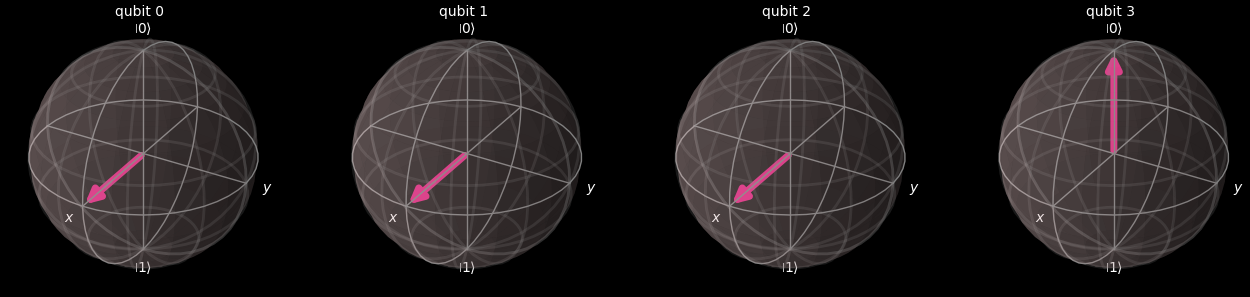

In [11]:
qpe = QuantumCircuit(3 + 1, 3)
qpe.h([0, 1, 2]) 

plot_bloch_multivector(qpe)

The resulting state is then, as seen:

$$\ket{\psi_1} = \frac{1}{\sqrt{2^m}} \sum_{j=0}^{2^m-1} \ket{j} \otimes \ket{\psi}$$

The application of the controlled oracular unitary operator follows next. Each qubit in the first register controls the application of $\hat U$ raised to increasing powers of 2 on the second register, because $$\hat U^j \ket{\psi} = e^{2\pi i \varphi j} \ket{\psi}$$ where $\varphi$ is currently unknown. This results in the state $$\ket{\psi_2} = \frac{1}{\sqrt{2^m}} \sum_{j=0}^{2^m-1} e^{2\pi i \varphi j} \ket{j} \otimes \ket{\psi}$$

Now we need an eigenvector of $\hat U$ to proceed. For simplicity, let's assume a simple unitary $\hat U=\text{diag}(1, e^{2\pi i\varphi})$ with eigenvector $\ket{\psi}=\ket{1}$ and eigenvalue $e^{2\pi i\varphi}$. This means that applying $\hat U$ to $\ket{1}$ results in a phase shift of $2\pi\varphi$, and a successive application of $\hat U^j$ results in a phase shift of $2\pi\varphi 2^j$. This is achieved in Qiskit using `RZ` gates, where each qubit in the first register controls the application of $\hat U$ raised to the power of $2^j$ on the second register.

Of course, this information would be encoded in **Fourier space,** so we'd need to introduce an **inverse QFT** to extract the phase information from the superposition state. Applying the inverse QFT to the first register transforms the state into a form where measuring the first register yields an estimate of $\varphi$ with high probability. I'll provide a helper function for the inverse QFT in the code for understanding, though it's integrated in Qiskit.

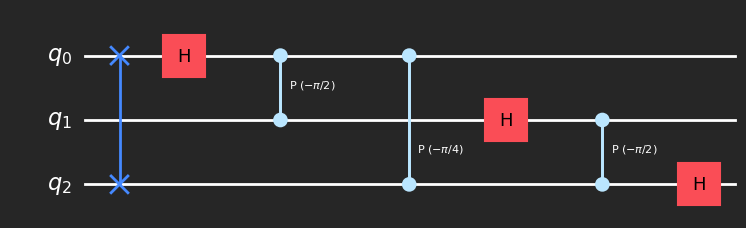

In [12]:
def inverse_qft(n):
    iqft = QuantumCircuit(n)
    
    for qubit in range(n // 2):
        iqft.swap(qubit, n - qubit - 1)
    
    for j in range(n):
        iqft.h(j)
        
        for m in range(j + 1, n):
            iqft.cp(-np.pi / (2 ** (m - j)), j, m)
    
    return iqft

draw_circuit(inverse_qft(3))

This is just for demonstrating how it looks. We'll apply this as a method `qiskit.circuit.library.QFT.inverse` to the first register for convenience. Finally, we measure the first register to obtain an estimate of the phase $\varphi$. The measurement collapses the superposition state into one of the basis states, and the result can be interpreted as a binary fraction that approximates $\varphi$.

The following code implements the QPE algorithm in full, with parameterized phase (guess) and customizable register sizes for $n$ and $m$. Feel free to experiment with different values of $\varphi$, $n$, and $m$ to see how they affect the accuracy of the phase estimation!

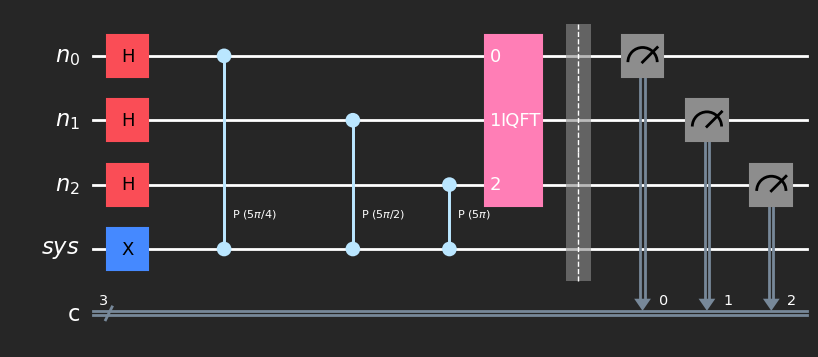

In [ ]:
def apply_phase_oracle_on_register(qc, counting_reg, system_qubit, varphi):

    for j, cq in enumerate(list(counting_reg)):
        theta = 2 * np.pi * varphi * (2 ** j)   # angle multiplies by 2^j
        qc.cp(theta, cq, system_qubit) # CROT from counting qubit cq to system_qubit with angle theta, should look like a downward staircase


def qpe_circuit(varphi, n_count, n_system, prepare_eigenstate = True, do_swaps = True): # eigenstate identification and swaps are done by default
    
    q_count = QuantumRegister(n_count, 'n')
    q_sys   = QuantumRegister(n_system, 'sys')
    creg    = ClassicalRegister(n_count, 'c')

    qc = QuantumCircuit(q_count, q_sys, creg)

    if prepare_eigenstate:
        qc.x(q_sys[0]) # Initialize system qubit to |1> state

    for qubit in q_count:
        qc.h(qubit) # Hadamard all counting qubits

    apply_phase_oracle_on_register(qc, q_count, q_sys[0], varphi) # apply controlled phase rotations

    qft_inv = QFT(num_qubits = n_count, inverse = True, do_swaps = do_swaps).to_instruction() # inverse QFT as a predefined instruction from Qiskit
    qc.append(qft_inv, list(q_count))

    qc.barrier()

    for i, qb in enumerate(q_count):
        qc.measure(qb, creg[i])

    return qc

# Phase guess between 0 and 1, feel free to customize the number of counting and system qubits!

phase = 0.625
n_count = 3
n_system = 1

draw_circuit(qpe_circuit(phase, n_count, n_system)) 

counts: {'101': 32768}


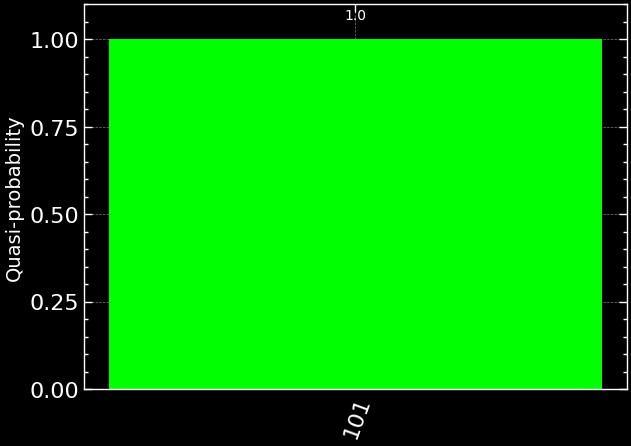

In [26]:
qc = qpe_circuit(0.625, n_count = 3, n_system = 1) # Redefining qc for brevity

backend = Aer.get_backend('aer_simulator')
tqc = transpile(qc, backend)

job = backend.run(tqc, shots = 2 ** 15) # More or less ideal shots
counts = job.result().get_counts()

print("counts:", counts)
plot_distribution(counts, color = 'lime')

Now $101_2 = 5_{10}$, which when divided by $2^3 = 8$ gives us $\varphi=0.625$. As the circuit is small, the estimation is exact. In practice, with larger circuits and more qubits, the estimation will be approximate, but it will converge to the true phase value as the number of qubits increases. 

That is, provided the phase guess is **binary-representable** with the number of counting qubits used. If not, the estimation will be the closest binary approximation to the true phase value. Try it out!

In [34]:
qc = qpe_circuit(0.69, n_count = 10, n_system = 4)

backend = Aer.get_backend('aer_simulator')
tqc = transpile(qc, backend)

job = backend.run(tqc, shots = 2 ** 15) 
counts = job.result().get_counts()

result = max(counts, key = counts.get)
phase = int(result, 2) / (2 ** 10)
print(f"Binary result: {result}, Estimated phase: {phase}")

Binary result: 1011000011, Estimated phase: 0.6904296875


This is a ridiculously massive circuit, but it ran very quickly, due to the fact we're using a noiseless simulator like Aer. Once we run the circuit on real quantum hardware, it'll get more time-consuming. Feel free to do so, although I'll only demonstrate it for VQE and QAOA later on.

# Checkpoint reached! Take a breather, and let's move on to the next algorithm in the following section.

***

# 2. The Variational Quantum Eigensolver

What is this? Why is it 'variational'? Well, the *Variational Quantum Eigensolver* (VQE) is a hybrid quantum-classical algorithm designed to find the **ground state energy** of a quantum system. It's particularly useful for simulating molecular systems and materials, where traditional methods struggle due to the exponential growth of the Hilbert space with system size. At its heart, VQE is a *Quantum Diagonalization Algorithm* that leverages the *Variational Principle* from quantum mechanics. Don't worry if you haven't heard of these terms before.

I'll recap or introduce you to diagonalization, and the variational principle individually for you here:

## Diagonalization of Operators

Diagonalization is a mathematical process used to simplify the representation of linear operators, particularly in the context of quantum mechanics and other fields relying on linear algebra. In quantum mechanics, physical observables (like energy, position, momentum) are represented by Hermitian operators (or self-adjoint operators). $\hat H=\hat H^\dagger$. Diagonalizing these operators means finding a basis in which the operator takes a diagonal form, making it easier to analyze and compute properties of the system.

As an example, consider a Hermitian operator $\hat H$ acting on a finite-dimensional Hilbert space $\mathcal H$. The diagonalization process involves finding a unitary transformation $\hat U$ such that $$\hat H' = \hat U^\dagger \hat H \hat U$$ is diagonal, where $\hat H'$ has eigenvalues $\lambda_i$ along its diagonal. The columns of $\hat U$ are the eigenvectors of $\hat H$, and the diagonal elements of $\hat H'$ correspond to the eigenvalues associated with these eigenvectors.

There's absolutely no need to probe deeper or do diagonalization by hand, since it gets ridiculously complicated for larger systems - exponentially larger matrices anyway. Just know that diagonalization is a way to simplify operators by finding a basis where they act like simple scaling operations on basis vectors.

## The Variational Principle

This principle is a fundamental concept in quantum mechanics that provides a method for approximating the ground state energy of a quantum system. It states that for any trial wavefunction $\ket{\psi}$, the expectation value of the Hamiltonian operator $\hat H$ with respect to this wavefunction provides an upper bound to the true ground state energy $E_0$ of the system. Mathematically, this is expressed as $$E[\psi] = \frac{\langle \psi | \hat H | \psi \rangle}{\langle \psi | \psi \rangle} \geq E_0$$ where $E[\psi]$ is the expectation value of the Hamiltonian for the trial wavefunction $\ket{\psi}$.

How is this useful? Well, by choosing a suitable trial wavefunction $\ket{\psi}$ (called an *ansatz*) and optimizing its parameters to minimize the expectation value $E[\psi]$, we can obtain an approximation of the ground state energy $E_0$. The closer our trial wavefunction is to the true ground state wavefunction, the more accurate our estimate of $E_0$ will be.

## Implementing VQE

We need, firstly a suitable Hamiltonian $\hat H$ that describes the quantum system of interest. We can either build it from scratch using a string of Paulis, or use Qiskit's chemistry module to generate one from molecular data. We'll choose the former for demonstration. 

A hydrogen molecule's a simple yet illustrative example. The molecular Hamiltonian for diatomic hydrogen is expressed (quite lengthily and tediously) as the sum of individual kinetic energies of nuclei and electrons, as well as the potential energies arising from their interactions. Don't worry about the details; these details and derivations are covered in depth in quantum chemistry courses. 

I tried using Qiskit's chemistry module to generate the Hamiltonian, but it kept throwing errors for different Python and NumPy versions, so I resorted to hardcoding the Hamiltonian here to avoid those issues for you guys.

In [11]:
hamiltonian = SparsePauliOp.from_list(
    [("YZ", 0.3980), ("ZI", -0.3980), ("ZZ", -0.0113), ("XX", 0.1810)]
)

print(hamiltonian)

SparsePauliOp(['YZ', 'ZI', 'ZZ', 'XX'],
              coeffs=[ 0.398 +0.j, -0.398 +0.j, -0.0113+0.j,  0.181 +0.j])


All we're concerned about is that it's Hermitian, and that's obviously true (there's no imaginary terms in any of the coefficients). NumPy has a built-in function to obtain the respective eigenvalues and eigenvectors. The minimum eigenvalue yields the ground state energy of the system, which we can compare our VQE results against later. Believe it or not, a size-4 or even a size-16 matrix is... quite small for quantum chemistry problems!

In [4]:
H = np.array(hamiltonian)
eigenvalues, eigenvectors = np.linalg.eigh(H)

print("The ground state energy is ", min(eigenvalues), "hartrees")

The ground state energy is  -0.702930394459531 hartrees


A Hartree is a unit of energy used in atomic physics and quantum chemistry, defined as twice the ionization energy of a hydrogen atom in its ground state. It is approximately equal to 27.2114 electronvolts.

We now need an ansatz or 'initial guess function', which is a parameterized quantum circuit that prepares a trial wavefunction $\ket{\psi(\vec{\theta})}$, with a set of paramters $\vec{\theta}$ to be optimized. Say a unitary $\hat U(\vec{\theta})$ such that $\ket{\psi(\vec{\theta})} = \hat U(\vec{\theta})\ket{0}^{\otimes n}$. The choice of ansatz is crucial, as it determines the expressibility of the trial wavefunction and the efficiency of the optimization process.

Since we're concerned about the expectation value of the Hamiltonian with respect to the trial wavefunction, we need to find the energy $E_j$ and its respective probability of occurrence $P_j$ for each eigenstate $\ket{\phi_j}$ of the Hamiltonian: $$\begin{align*}E(\vec{\theta}) = \sum_j P_j(\vec{\theta}) E_j&&&&P_j(\vec{\theta}) = |\langle \phi_j | \psi(\vec{\theta}) \rangle|^2\end{align*}$$ where $E_j$ are the eigenvalues of $\hat H$.

In Qiskit, we can use predefined ansatz circuits like `EfficientSU2`, or we can construct custom ansatz circuits based on the specific problem. For simplicity, we'll use the `EfficientSU2` ansatz, which is a commonly used ansatz for VQE due to its balance between expressibility and circuit depth.

This circuit has  10 parameters


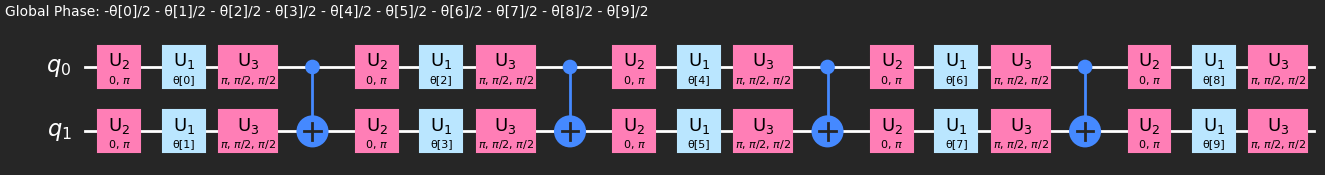

In [45]:
ansatz = efficient_su2(
    hamiltonian.num_qubits, su2_gates = ["h", "rz", "y"], entanglement = "circular", reps = 4
)
 
num_params = ansatz.num_parameters
print("This circuit has ", num_params, "parameters")
 
draw_circuit(ansatz.decompose())

This looks admittedly nightmarish, but it's just a series of parameterized rotation gates and entangling CNOT gates. The parameters $\vec{\theta}$ are initialized randomly and will be optimized during the VQE process. Now, you might be thinking - can't we just use the estimator class in Qiskit to compute the expectation value directly, like $$E\approx\frac 1N\sum\limits_{j=1}^NE_j$$ Besides appearing deceptively simple, this approach has a major drawback; it's only valid in the limit of large $N$, which is impractical for real quantum hardware due to noise and decoherence. Instead, VQE uses a more sophisticated approach that involves measuring the expectation value of the Hamiltonian directly on the quantum hardware, which is more efficient and robust against noise. It's also classically intractable for larger systems, with computational complexity $O(n^2)$.

VQE relies on **hamiltonian decomposition** through a weighted sum for expressibility as a Pauli string. This allows us to measure the expectation value of each term separately and combine them to obtain the total energy. The Hamiltonian can be decomposed as $$\hat H = \sum_k c_k \hat P_k$$ where $c_k$ are coefficients and $\hat P_k$ are tensor products of Pauli operators $(\hat I_2,\hat X,\hat Y, \hat Z)$. Additionally, to solve the commutation issues between different Pauli strings during measurement, we can group commuting Pauli strings together and measure them simultaneously. This reduces the number of measurements required and improves the efficiency of the algorithm.

Back to our ansatz circuit, we can run it on a local estimator for Open Plan users. I'll run on real hardware for funzies, but feel free to use the Aer simulator for faster and noiseless results. If you decide to run on real hardware, make sure to choose a backend with enough qubits and low noise levels for better accuracy, and also load your IBMQ account if you haven't already. If stuck, I've detailed the steps in my [introduction to Qiskit notebook](introduction.ipynb).

In [46]:
service = QiskitRuntimeService()
backend = service.least_busy(operational = True, simulator = False)
 
print(backend, backend.num_qubits)

qiskit_runtime_service._resolve_cloud_instances:WARNING:2025-12-15 02:07:46,955: Default instance not set. Searching all available instances.


<IBMBackend('ibm_fez')> 156


The last line maps the target Hamiltonian to the ansatz circuit, allowing us to measure the expectation value of the Hamiltonian with respect to the trial wavefunction prepared by the ansatz. Don't miss this step! We'll now define a cost function that takes in absolutely everything we need to compute the expectation value of the Hamiltonian for a given set of parameters $\vec{\theta}$. This function will be used by the classical optimizer to minimize the energy.

In [47]:
def cost_function(params, ansatz, hamiltonian, estimator):
    """
    Cost function using EstimatorV1 interface.
    """

    pub = (ansatz, [hamiltonian], [params])
    result = estimator.run([pub]).result()

    # Extract the energy
    energy = result[0].data.evs[0]

    # Track history
    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = params
    cost_history_dict["cost_history"].append(energy)

    return energy

cost_history_dict = {

    "prev_vector": None,
    "iters": 0,
    "cost_history": [],

}

To choose our initial parameters, we can use random values or specific initial guesses based on prior knowledge of the system. Here, we'll use random values for simplicity. Take a wild guess!

In [52]:
x_0 = np.random.uniform(0, np.pi, num_params) # Rotations in SU(2) are usually 2pi-periodic
x_0

array([1.51302354, 2.22186203, 1.19513267, 1.33016934, 2.86205253,
       0.32748715, 1.07240951, 0.6076    , 0.91381483, 0.95320198])

In [53]:
results_dict = {}
methods = ['COBYLA', 'Powell', 'Nelder-Mead', 'L-BFGS-B', 'SLSQP']

# Run optimization for each method
for method in methods:
    
    print(f"\n{'='*60}")
    print(f"Running optimization with {method} method...")
    print('='*60)
    
    cost_history_dict = {
        
        "prev_vector": None,
        "iters": 0,
        "cost_history": [],
    
    }
    
    start_time = time()
    estimator = StatevectorEstimator()
    
    res = minimize(
        
        cost_function,
        x_0,
        args = (ansatz, hamiltonian, estimator),
        method = method,
        options = {"maxiter": 50},
    
    )
    
    end_time = time()
    elapsed_time = end_time - start_time
    
    results_dict[method] = {
        
        'result': res,
        'time': elapsed_time,
        'cost_history': cost_history_dict['cost_history'].copy(),
        'iterations': cost_history_dict['iters']
    
    }
    
    print(f"\nOptimization completed in {elapsed_time:.2f} seconds ({elapsed_time/60:.2f} minutes)")
    print(f"Final energy: {res.fun:.8f} Hartrees")
    print(f"Number of iterations: {cost_history_dict['iters']}")


Running optimization with COBYLA method...

Optimization completed in 0.35 seconds (0.01 minutes)
Final energy: -0.69447702 Hartrees
Number of iterations: 50

Running optimization with Powell method...

Optimization completed in 4.23 seconds (0.07 minutes)
Final energy: -0.70291633 Hartrees
Number of iterations: 630

Running optimization with Nelder-Mead method...

Optimization completed in 0.48 seconds (0.01 minutes)
Final energy: -0.48292091 Hartrees
Number of iterations: 74

Running optimization with L-BFGS-B method...

Optimization completed in 2.18 seconds (0.04 minutes)
Final energy: -0.70293039 Hartrees
Number of iterations: 297

Running optimization with SLSQP method...

Optimization completed in 1.06 seconds (0.02 minutes)
Final energy: -0.70293035 Hartrees
Number of iterations: 154


Here's a method comparison plot:

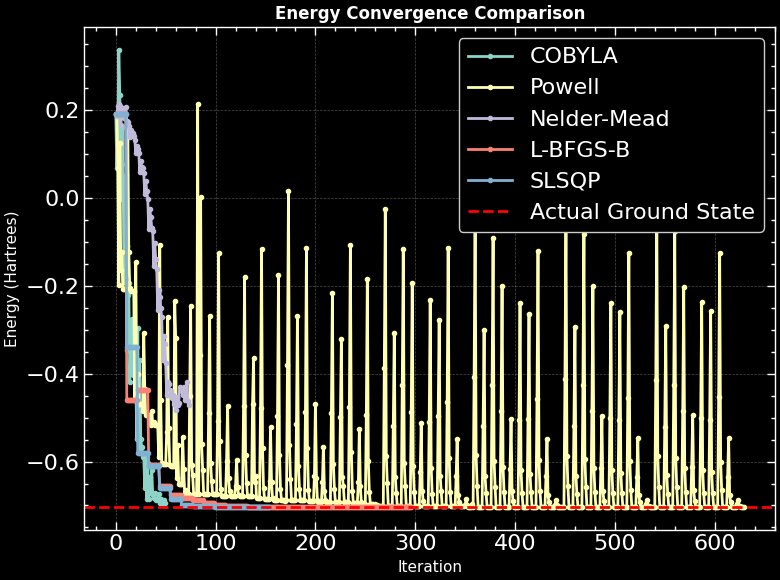

In [54]:
for method in methods:
    
    history = results_dict[method]['cost_history']
    plt.plot(history, label = method, linewidth = 2, marker = 'o', markersize = 3)

plt.axhline(y = min(eigenvalues), color = 'red', linestyle = '--', linewidth = 2, label = 'Actual Ground State')
plt.xlabel('Iteration', fontsize = 11)
plt.ylabel('Energy (Hartrees)', fontsize = 11)

plt.title('Energy Convergence Comparison', fontsize = 12, fontweight = 'bold')
plt.legend()
plt.grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

I know this looks cursed in terms of the Powell method convergence, but hey, it works! As you can see, different optimizers converge to the ground state energy at different rates. The choice of optimizer can significantly impact the performance of the VQE algorithm, so it's worth experimenting with different options to find the best fit for your specific problem. From what we see here, Powell is very slow but eventually converges quite well, while L-BFGS-B is wildly early to converge after just a few messy iterations.

Try it out with a different sized Hamiltonian, ansatz, and optimizer of your choice! You can also experiment with different initial parameter guesses (say just the first or first two quadrants of a unit circle) to see how they affect the convergence of the algorithm.

# PANIC CODEBLOCK: CANCEL ALL QUEUED JOBS (OPEN PLAN USERS)

In [ ]:
jobs = service.jobs(limit = 20)
for job in jobs:
    if not job.in_final_state():   # queued or running
        print(f"Cancelling job {job.job_id()} (status = {job.status()})")
        job.cancel()

Post processing is admittedly strange. Let me just show you. First, we extract the energies from the results object, then compare with our exact diagonalization result. I'll choose Powell, but you can choose any optimizers of your choice.

In [56]:
energies = np.array(results_dict['L-BFGS-B']['cost_history'])
best_energies = np.minimum.accumulate(energies)

print(best_energies)

[ 0.1910987   0.1910987   0.1910987   0.1910987   0.1910987   0.1910987
  0.1910987   0.1910987   0.1910987   0.1910987   0.1910987  -0.46021624
 -0.46021624 -0.46021624 -0.46021624 -0.46021624 -0.46021625 -0.46021625
 -0.46021625 -0.46021625 -0.46021625 -0.46021625 -0.46021625 -0.46021625
 -0.46021625 -0.46021625 -0.46021625 -0.46021625 -0.46021625 -0.46021625
 -0.46021625 -0.46021625 -0.46021625 -0.606902   -0.606902   -0.606902
 -0.606902   -0.606902   -0.606902   -0.606902   -0.606902   -0.606902
 -0.606902   -0.606902   -0.6546705  -0.6546705  -0.6546705  -0.6546705
 -0.6546705  -0.6546705  -0.6546705  -0.6546705  -0.6546705  -0.6546705
 -0.6546705  -0.67519563 -0.67519563 -0.67519563 -0.67519563 -0.67519563
 -0.67519563 -0.67519563 -0.67519563 -0.67519563 -0.67519563 -0.67519563
 -0.68397135 -0.68397135 -0.68397135 -0.68397135 -0.68397135 -0.68397135
 -0.68397135 -0.68397135 -0.68397135 -0.68397135 -0.68397135 -0.6885514
 -0.6885514  -0.6885514  -0.6885514  -0.6885514  -0.6885514

Naturally, the best energy is the last element in this list. Let's print it out alongside the exact diagonalization result for comparison.

In [57]:
print(f"VQE Energy: {best_energies[-1]:.6f} Hartrees")
print(f"Exact Ground State: {min(eigenvalues):.6f} Hartrees")
print(f"Error: {abs(best_energies[-1] - min(eigenvalues)):.6f} Hartrees, with relative error {abs(best_energies[-1] - min(eigenvalues)) / abs(min(eigenvalues)):.6%}")

VQE Energy: -0.702930 Hartrees
Exact Ground State: -0.702930 Hartrees
Error: 0.000000 Hartrees, with relative error 0.000000%


That's it! You've successfully implemented the VQE algorithm to estimate the ground state energy of a hydrogen molecule using a parameterized ansatz circuit and a classical optimizer. Feel free to experiment with different Hamiltonians, ansatz circuits, and optimizers to explore the capabilities of the VQE algorithm further.

***

# Checkpoint reached! Take a breather, and let's move on to the next algorithm in the following section.

# 3. Trotterization

This 'algorithm' is more of an approximation technique used in solving numerically, a special type of problem in time-evolution, which we discussed earlier in the [Quantum Phase Estimation](#quantum-phase-estimation) section. It might sound trivial to assume that $e^{\hat A+\hat B} = e^{\hat A}e^{\hat B}$ for non-commuting operators $\hat A$ and $\hat B$, but it's **not true** in general (it's true **just** for scalars, not matrices). This is because the order of operations matters when dealing with non-commuting operators, leading to additional terms in the expansion of the exponential that cannot be captured by simply multiplying the exponentials of the individual operators. 

The Lie product formula provides a way to approximate the exponential of a sum of non-commuting operators by breaking it down into a product of exponentials of the individual operators, as $$e^{\hat A + \hat B} = \lim_{n \to \infty} \left(e^{\hat A/n} e^{\hat B/n}\right)^n.$$

As you (hopefully) recall, time evolution of a state or system is governed by the time-evolution operator $\hat U(t, t_0) = e^{-i\hat H(t-t_0)/\hbar}$, where $\hat H$ is the Hamiltonian of the system. The system Hamiltonian can often be decomposed into a sum of simpler terms, say $\hat H = \sum_k \hat H_k$, where each $\hat H_k$ represents a different interaction or component of the system, but the time-evolution operator becomes $$\hat U(t, t_0) = \exp\left[-i\sum_k\frac{\hat H_k (t-t_0)}{\hbar}\right]$$ which is difficult to compute directly due to the presumably non-commuting nature of the $\hat H_k$ terms.

Trotterization comes to the rescue here. By applying the Lie product formula, we can approximate the time-evolution operator as $$\hat U(t, t_0) \approx \left(\prod_k\exp\left[-i\frac{\hat H_k (t-t_0)}{n\hbar}\right]\right)^n$$ for a sufficiently large $n$. This approximation allows us to simulate the time evolution of the system by sequentially applying the exponentials of the individual Hamiltonian terms, which are often easier to implement on a quantum computer.

Say t/n is the evolution step size, then each term $\exp\left[-i\dfrac{\hat H_k (t-t_0)}{n\hbar}\right]$ can be implemented as a quantum gate or a series of gates, depending on the specific form of $\hat H_k$. By repeating this process $n$ times (ideally very large), we can approximate the overall time evolution of the system over the interval $[t_0, t]$. The error scales with $O\left[\dfrac{(t-t_0)^2}{n}\right]$, so increasing $n$ improves the accuracy of the approximation. For this reason, Trotterization is widely used in simulating quantum systems and solving time-dependent Schrödinger equations. 

Let's try it out in Qiskit! We'll simulate the time evolution of a simple two-qubit system with a Hamiltonian that includes both local and interaction terms. We'll use Trotterization to approximate the time-evolution operator and implement it as a quantum circuit.

In [20]:
H = SparsePauliOp.from_list([
    ("XI", 1.0),
    ("IZ", 1.0),
    ("YY", 0.8),
    ("ZX", 0.6),
])

First-order Trotterization is straightforward to implement. We use the `LieTrotter` class from Qiskit to create a Trotterized time-evolution operator for our Hamiltonian. This basically breaks down $$\hat U(t, t_0 = 0) \approx e^{-i\hat H_1t/\hbar}e^{-i\hat H_2t/\hbar}+O(t^2/n)$$ into a quantum circuit.

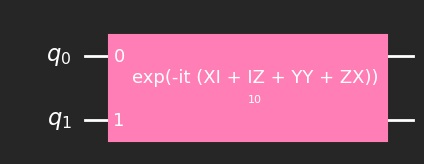

In [21]:
t = 10.0
n = 10000   # number of Trotter steps

evolution = PauliEvolutionGate(
    H,
    time = t,
    synthesis = LieTrotter(reps = n)
)

lie = QuantumCircuit(H.num_qubits)
lie.append(evolution, lie.qubits)

draw_circuit(lie)

Trying with another method `SuzukiTrotter`, which implements higher-order Trotterization methods for improved accuracy; Here, we use a second-order decomposition, which provides a better approximation of the time-evolution operator by symmetrically applying the exponentials of the Hamiltonian terms: $$\hat U(t, t_0 = 0) \approx e^{-i\hat H_1t/2\hbar}e^{-i\hat H_2t/\hbar}e^{-i\hat H_1t/2\hbar}+O(t^3/n^2)$$

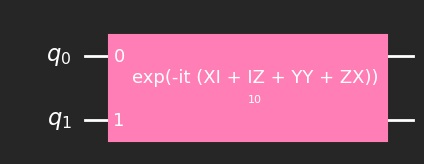

In [22]:
t = 10.0
n = 10000   # number of Trotter steps

evolution = PauliEvolutionGate(
    H,
    time = t,
    synthesis = SuzukiTrotter(reps = n, order = 2)
)

st = QuantumCircuit(H.num_qubits)
st.append(evolution, st.qubits)

draw_circuit(st)

In [23]:
from scipy.linalg import expm

psi0 = Statevector.from_label("00")

psi_exact = psi0.evolve(expm(-1j * H.to_matrix() * t))
psi_lie = psi0.evolve(lie)
psi_st = psi0.evolve(st)

fidelity_lie = abs(psi_exact.data.conj() @ psi_lie.data) ** 2
fidelity_st = abs(psi_exact.data.conj() @ psi_st.data) ** 2
print("Fidelity (Lie Trotter):", fidelity_lie)
print("Fidelity (Suzuki Trotter):", fidelity_st)

Fidelity (Lie Trotter): 0.9999997340671499
Fidelity (Suzuki Trotter): 0.9999999999893527


Very very good! The number of Trotter steps determines the accuracy of the approximation, with more steps leading to a closer approximation of the true time-evolution operator. Let's examine the fidelity error behavior with increasing Trotter steps graphically:

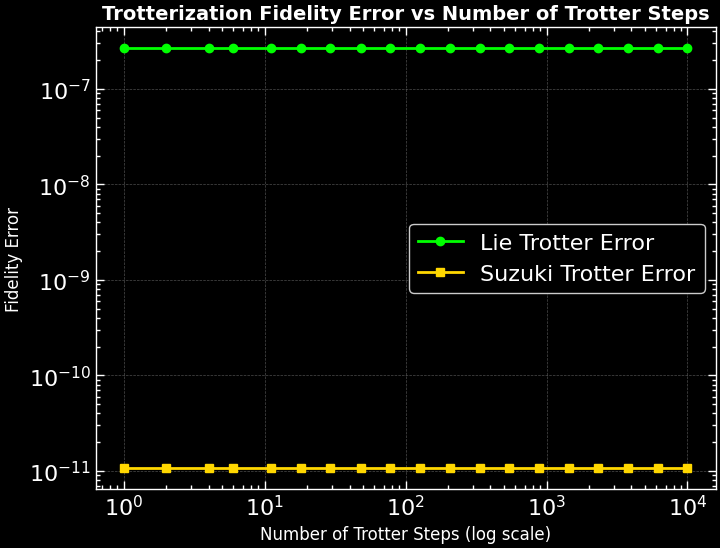

In [31]:
trotter_steps = np.arange(1, 100)

plt.xscale('log')
plt.yscale('log')
plt.title('Trotterization Fidelity Error vs Number of Trotter Steps', fontsize = 14, fontweight = 'bold')
plt.xlabel('Number of Trotter Steps (log scale)', fontsize = 12)
plt.ylabel('Fidelity Error', fontsize = 12)

lie_errors = []
suzuki_errors = []

n_steps = np.unique(np.logspace(0, 4, num = 20, dtype = int))

for n in n_steps:
    
    qc_lie = QuantumCircuit(H.num_qubits)
    lie_gate = PauliEvolutionGate(
        H,
        time = t,
        synthesis=LieTrotter(reps = n)
    )
    qc_lie.append(lie_gate, qc_lie.qubits)
    lie_errors.append(fidelity_lie)

    qc_st = QuantumCircuit(H.num_qubits)
    st_gate = PauliEvolutionGate(
        H,
        time = t,
        synthesis=SuzukiTrotter(order = 2, reps = n)
    )
    qc_st.append(st_gate, qc_st.qubits)
    suzuki_errors.append(fidelity_st)

plt.grid(True, alpha = 0.3)
plt.plot(n_steps, 1 - np.array(lie_errors), label = 'Lie Trotter Error', marker = 'o', color = 'lime')
plt.plot(n_steps, 1 - np.array(suzuki_errors), label = 'Suzuki Trotter Error', marker = 's', color = 'gold')
plt.legend()

Ugly Hamiltonians pronounce this error trend better, but that's not our concern here. As you can see, Suzuki-Trotterization provides a significantly better approximation of the time-evolution operator compared to first-order Trotterization, especially as the number of Trotter steps increases. This may have been expected, but maybe not to such a large degree!

As an exercise, try implementing Trotterization for a more complex Hamiltonian, such as one representing a small molecule or a spin chain. Experiment with different numbers of Trotter steps and compare the results to see how the accuracy of the approximation improves with increasing steps. Also, feel free to explore higher-order Trotterization methods and see how they affect the fidelity of the time-evolution operator. You can try to express third-order or first-order Trotterization on paper (based on the general formula I provided) and implement them in Qiskit as custom circuits!

And that's it for Trotterization! You've successfully implemented both first-order and second-order Trotterization methods to approximate the time-evolution operator for a simple two-qubit system. Trotteriation and VQE often go hand-in-hand in quantum simulations, because the ansatz is often trotterized, with the `reps` argument controlling the number of Trotter steps!

***

# 4. The Quantum Approximate Optimization Algorithm

Here we are, finally! The *Quantum Approximate Optimization Algorithm* (QAOA) is a hybrid quantum-classical algorithm designed to solve **combinatorial optimization** problems. It was introduced by Farhi et al. in 2014 and has proven to be particularly well-suited for problems that can be formulated as finding the ground state of a classical Hamiltonian or, equivalently, maximizing a cost function defined over binary variables. 

Now, you might be thinking, this is just used in math and computer science, but combinatorial optization is key in some physical systems too! For example, in statistical mechanics, finding the ground state of a spin model can be formulated as such, alongside certain molecular structure problems mappable to optimization problems that QAOA can tackle.

A short primer on combinatorics is in order. Working in bits is physically awkward, so we can use spin variables instead, where each bit $b_i\in\{0, 1\}$ is mapped to a spin variable $s_i=(-1)^{b_i}\in\{-1, +1\}$. This mapping allows us to the problem in terms of spin configurations, which is more natural in the context of quantum mechanics, as spins are fundamental quantum degrees of freedom, given by the eigenvalues of $\hat\sigma_Z$.

Let's jump to quantum problems from here. Instead of bits, we use Paulis. Instead of a cost function needing to be minimized, we use a **cost Hamiltonian** $\hat H_C$, whose ground state corresponds to the optimal solution of the original problem. The cost Hamiltonian is **diagonal** in the computational basis, encoding the problem's objective function as energy levels. Follow me? 

All you need to know to start is the transitioning from bits to spins, and from cost functions to cost Hamiltonians. Mathematically, $$C(z)=\min_{z\in\{0,1\}^n}\tilde C(z) \longrightarrow \hat H_C\ket{z} = E_0\ket{z}$$ where $E_0$ is the ground state energy of $\hat H_C$.

We'll consider a pure physics problem for demonstration - the Ising model, which describes a system of spins on a lattice that can interact with each other and with an external transverse magnetic field with strength $h$. The Hamiltonian for the Ising model is given by $$\hat H = -J\sum_{\langle i,j \rangle} \hat \sigma_Z^{(i)} \hat \sigma_Z^{(j)} - h\sum_i \hat \sigma_X^{(i)}$$ where $J$ is the interaction strength between neighboring spins, $h$ is the external magnetic field strength, and $\langle i,j \rangle$ denotes pairs of neighboring spins.

The notation $\langle i,j \rangle$ indicates that the summation is taken over all pairs of **neighboring spins** in the lattice (remember, spins do influence each other). In the one-dimensional chain, this'd mean summing over pairs of spins that are adjacent to each other. We won't bother with higher dimensions here, but do note that the boundary conditions apply a periodicity, so that the first and last spins in the chain are also considered neighbors, effectively forming a closed loop.

That's all for now, I don't wanna overwhelm you. Let's learn as we code. First, we build a Hamiltonian for a customizable periodic chain of spins:

In [53]:
def transverse_field_ising(n, J, h):
    
    paulis = []
    coeffs = []

    for i in range(n - 1):
        
        label = ["I"] * n
        label[i] = "Z"
        label[i + 1] = "Z"
        paulis.append("".join(label))
        coeffs.append(-J)

    for i in range(n):
        
        label = ["I"] * n
        label[i] = "X"
        paulis.append("".join(label))
        coeffs.append(-h)

    return SparsePauliOp(paulis, coeffs)

# Experiment with different J, h, and n values

J = 1.0
h = 1.0
n_qubits = 8

H_ising = transverse_field_ising(n_qubits, J = J, h = h)
print(H_ising)

SparsePauliOp(['ZZIIIIII', 'IZZIIIII', 'IIZZIIII', 'IIIZZIII', 'IIIIZZII', 'IIIIIZZI', 'IIIIIIZZ', 'XIIIIIII', 'IXIIIIII', 'IIXIIIII', 'IIIXIIII', 'IIIIXIII', 'IIIIIXII', 'IIIIIIXI', 'IIIIIIIX'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j,
 -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j])


We can split this Hamiltonian into a 'cost term' $\hat H_C = -J\sum_{\langle i,j \rangle} \hat \sigma_Z^{(i)} \hat \sigma_Z^{(j)}$ and a 'mixer term' $\hat H_M = - h\sum_i \hat \sigma_X^{(i)}$. The cost term encodes the problem we want to solve, while the mixer term introduces quantum fluctuations that help explore the solution space. In practice, this basically means we separate the $\hat Z\otimes\hat Z$ interactions and the $\hat X$ rotations.

Both terms can be implemented as quantum circuits using parameterized gates. The cost term can be implemented using controlled-Z gates and phase rotations, while the mixer term can be implemented using single-qubit X-rotations: $e^{i\beta JZ_iZ_j}=RZZ(2\beta J)$ and $e^{i\gamma hX_i}=RX(2\gamma h)$

Of course, we're evolving in time, so guess who's back? Trotterization! We'll use Trotterization to approximate the time-evolution operator for both the cost and mixer Hamiltonians, as $$\begin{align*}U_C(\beta) &= e^{-i\hat H_C \beta} \approx \prod_{\langle i,j \rangle} e^{iJ\hat \sigma_Z^{(i)} \hat \sigma_Z^{(j)} \beta} \\ U_M(\gamma) &= e^{-i\hat H_M \gamma} \approx \prod_i e^{ih\hat \sigma_X^{(i)} \gamma}\end{align*}$$ where $\beta$ and $\gamma$ are parameters that control the evolution time for the cost and mixer Hamiltonians, respectively.

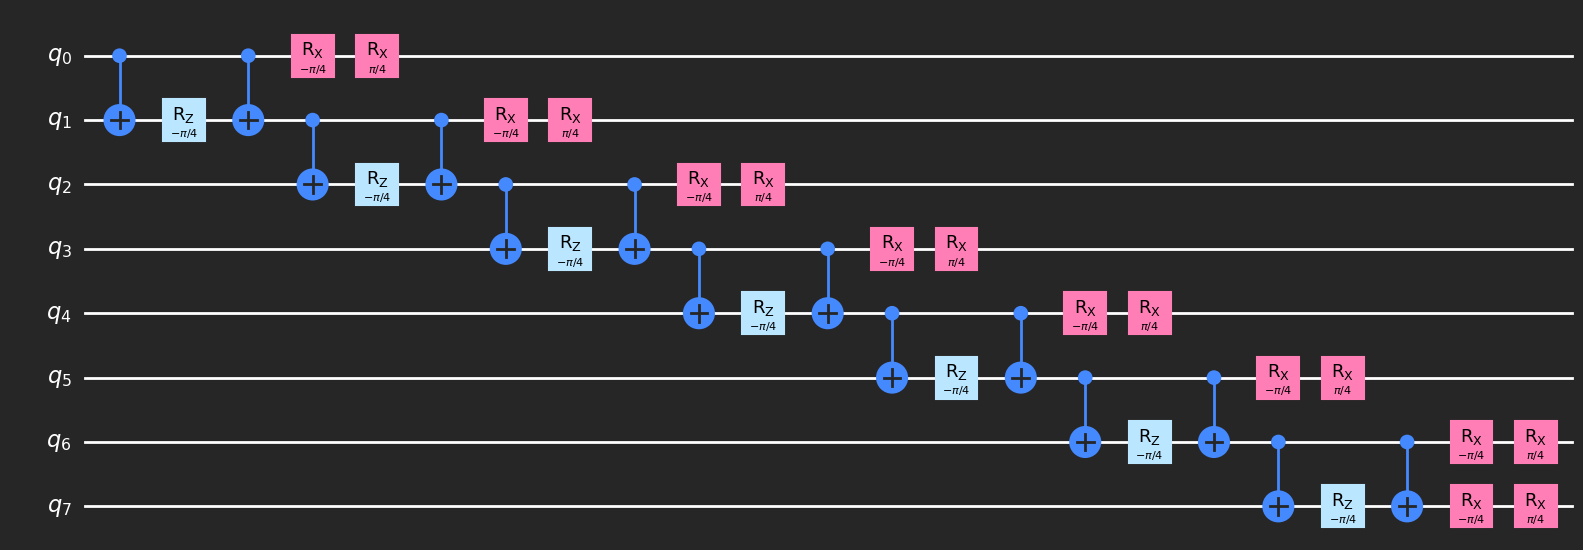

In [54]:
def qaoa_layer(beta, gamma, hamiltonian, n_qubits):

    layer = QuantumCircuit(n_qubits)

    for pauli, coeff in zip(hamiltonian.paulis.to_labels(), hamiltonian.coeffs):
        if pauli.count("Z") == 2:  # ZZ interaction
            
            qubits = [i for i, p in enumerate(pauli) if p == "Z"]
            
            layer.cx(qubits[0], qubits[1])
            layer.rz(2 * coeff.real * beta, qubits[1])
            layer.cx(qubits[0], qubits[1])
        
        elif pauli.count("X") == 1:  # X term
            
            qubit = pauli.index("X")
            layer.rx(2 * coeff.real * beta, qubit)

    # Mixer Hamiltonian evolution
    
    for i in range(n_qubits):
        layer.rx(2 * gamma, i)

    return layer

# Customize beta and gamma as fractions of pi

beta = np.pi / 8
gamma = np.pi / 8

draw_circuit(qaoa_layer(beta, gamma, H_ising, n_qubits))

This is the QAOA layer.

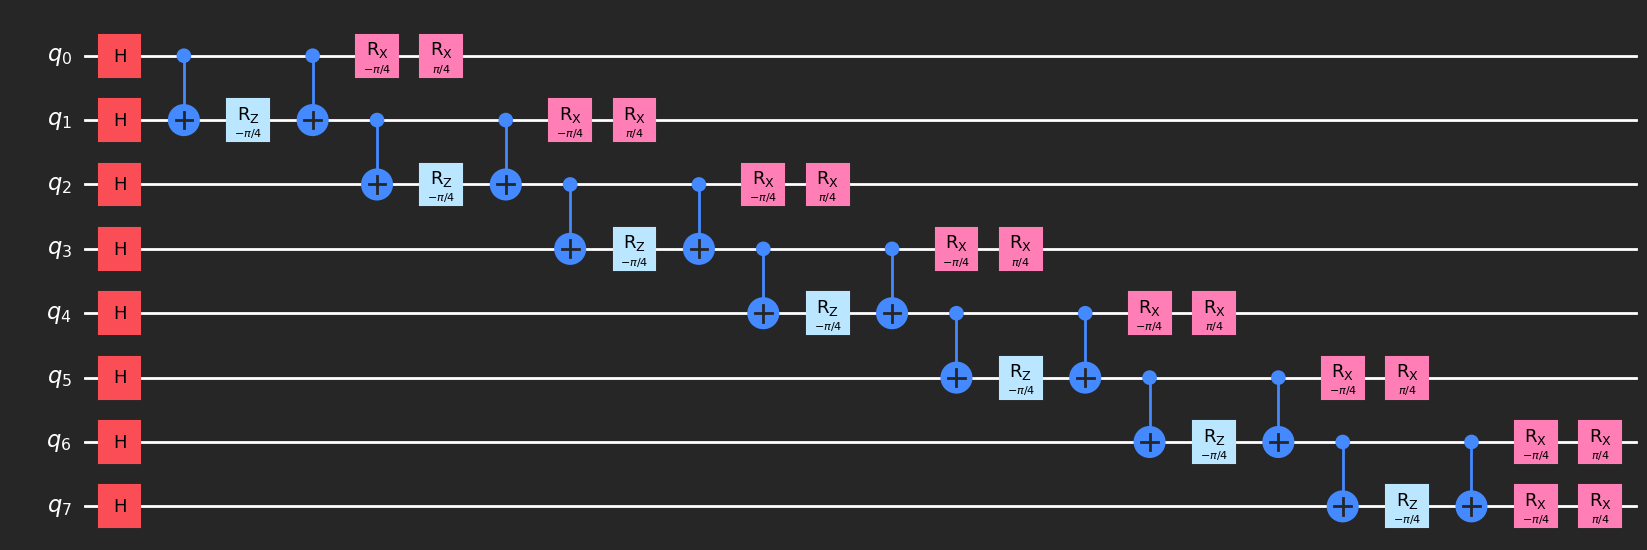

In [55]:
ising = QuantumCircuit(n_qubits)
ising.h(range(n_qubits))  # Initialize to |+> state

ising.compose(qaoa_layer(beta, gamma, H_ising, n_qubits), inplace = True)
draw_circuit(ising)

This is mathematically, $$\ket\psi=e^{-i\beta H_X}e^{-i\gamma H_Z}\ket{+}^{\otimes n}$$ 

Finally, we measure the expectation value of the cost Hamiltonian with respect to the state prepared by the QAOA circuit. This expectation value serves as the objective function for the classical optimizer, which adjusts the parameters $\vec{\beta}$ and $\vec{\gamma}$ to minimize the energy.

In [56]:
psi = Statevector.from_instruction(ising)
ev = psi.expectation_value(H_ising).real

print("Expectation value of the cost Hamiltonian:", ev, "units", "for beta =", beta / np.pi, "π and gamma =", gamma / np.pi, "π")

Expectation value of the cost Hamiltonian: -4.414213562373085 units for beta = 0.125 π and gamma = 0.125 π


In [57]:
print("Actual energy: ", np.min(np.linalg.eigvals(H_ising.to_matrix())).real, "units")

Actual energy:  -9.83795144745945 units


It's not terrible, but we can do much better. Thing is, we only used one Trotter layer, or a first-order Trotter approximation. Let's set the number of layers to a comfortable but adamant 4.

In [ ]:
n_layers = 4

for _ in range(n_layers - 1):
    ising.compose(qaoa_layer(beta, gamma, H_ising, n_qubits), inplace = True)

psi = Statevector.from_instruction(ising)
ev = psi.expectation_value(H_ising).real

print(f"Expectation value after {n_layers} layers:", ev, "units")

Expectation value after 4 layers: -3.999999999999988 units


Note that sometimes this can give extremely low energies, near zero, which is unphysical. This is likely due to overfitting or the optimizer getting stuck in exponentially many local minima. To mitigate this, we can try different initial parameter guesses, use more robust optimizers, or increase the number of layers to provide more flexibility in the ansatz. 

Regardless of whether the new results are closer or farther away, we can implement a simple parameter sweep with a classical optimizer to visualize how the energy landscape changes with different values of number of layers, $\beta$ and $\gamma$. This can help us understand the optimization process better and identify potential issues with local minima, and this'd work for your qubit and layer configuration too! 

In [87]:
betas = np.linspace(0, 2 * np.pi, 30)
gammas = np.linspace(0, np.pi, 30)

layer_list = np.arange(1, 5 + 1)  # You can change this to any number of layers you want to test
best_energy_per_layer = {}

print("Starting sweep...")

for n_layers in layer_list:

    energy_landscape = np.zeros((len(betas), len(gammas)))

    print(f"\nSweeping for n_layers = {n_layers}")

    for i, b in enumerate(betas):

        for j, g in enumerate(gammas):

            qc_sweep = QuantumCircuit(n_qubits)
            qc_sweep.h(range(n_qubits))

            for _ in range(n_layers):
                
                qc_sweep.compose(
                    
                    qaoa_layer(b, g, H_ising, n_qubits),
                    inplace = True
                
                )

            psi_sweep = Statevector.from_instruction(qc_sweep)
            energy_landscape[i, j] = psi_sweep.expectation_value(H_ising).real

    best_energy = np.min(energy_landscape)
    best_energy_per_layer[n_layers] = best_energy

    print(f"Best error margin is for {n_layers} layer(s): {abs(best_energy - eigenvalues.min()):.6f} units")

Starting sweep...

Sweeping for n_layers = 1
Best error margin is for 1 layer(s): 0.378236 units

Sweeping for n_layers = 2
Best error margin is for 2 layer(s): 0.346720 units

Sweeping for n_layers = 3
Best error margin is for 3 layer(s): 0.394928 units

Sweeping for n_layers = 4
Best error margin is for 4 layer(s): 0.505585 units

Sweeping for n_layers = 5
Best error margin is for 5 layer(s): 0.961016 units


For reasons we shouldn't concern ourselves with for now, $\beta$ is $2\pi$-periodic and $\gamma$ is $\pi$-periodic. This means that when sweeping the parameters, we only need to consider values within these ranges to capture the full behavior of the energy landscape.

The loop takes care of everything, but let's go opimal layers first, and then plot our parameters to better visualize the energy landscape and minima.

In [88]:
optimal_layers = min(best_energy_per_layer, key = best_energy_per_layer.get)
best_energy = best_energy_per_layer[optimal_layers]

print(f"\nOptimal number of layers: {optimal_layers}")
print(f"Energy: {best_energy:.6f} units and error: {abs(best_energy - eigenvalues.min()):.6f} units")


Optimal number of layers: 2
Energy: -9.491231 units and error: 0.346720 units


There's our optimal Trotter layers. Now, let's see the energy landscape as a function of the parameters $\beta$ and $\gamma$. I've implemented a contour plot, letting you visualize how the energy varies across different parameter values.

c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


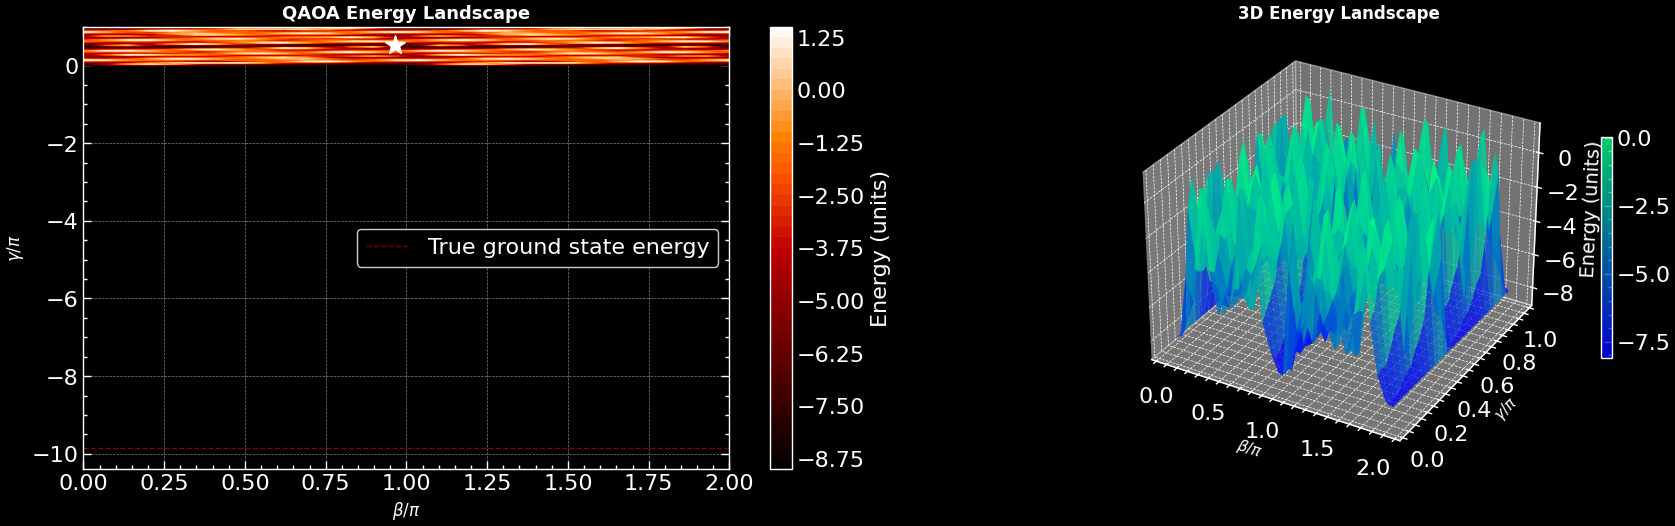


Optimal parameters found: β = 3.0333 (0.9655π), γ = 1.6250 (0.5172π)
Energy at optimal point: -8.876935 units
True ground state energy: -9.837951 units
Error: 0.961016 units


In [89]:
eigenvalues = np.linalg.eigvals(H_ising.to_matrix())

plt.figure(figsize = (18, 6))
plt.subplot(1, 2, 1)

im = plt.contourf(betas / np.pi, gammas / np.pi, energy_landscape, levels = 50, cmap = 'gist_heat')

plt.colorbar(im, label = 'Energy (units)')

plt.xlabel(r'$\beta / \pi$', fontsize = 12)
plt.ylabel(r'$\gamma / \pi$', fontsize = 12)
plt.title('QAOA Energy Landscape', fontsize = 13, fontweight = 'bold')
plt.axhline(y = min(eigenvalues), color = 'red', linestyle = '--', linewidth = 1, alpha = 0.5, label = 'True ground state energy') # True ground state energy line
plt.legend()

min_idx = np.unravel_index(np.argmin(energy_landscape), energy_landscape.shape)
optimal_beta = betas[min_idx[0]]
optimal_gamma = gammas[min_idx[1]]

plt.plot(optimal_beta / np.pi, optimal_gamma / np.pi, 'w*', markersize = 15, label = 'Minimum')

ax = plt.subplot(1, 2, 2, projection = '3d')
Beta, Gamma = np.meshgrid(betas / np.pi, gammas / np.pi)
surf = ax.plot_surface(Beta, Gamma, energy_landscape.T, cmap = 'winter', alpha = 0.8)

ax.set_xlabel(r'$\beta / \pi$', fontsize = 11)
ax.set_ylabel(r'$\gamma / \pi$', fontsize = 11)
ax.set_zlabel('Energy (units)', fontsize = 14)
ax.set_title('3D Energy Landscape', fontsize = 12, fontweight = 'bold')

plt.colorbar(surf, ax = ax, shrink = 0.5)
plt.tight_layout(pad = 3.0)
plt.show()

print(f"\nOptimal parameters found: β = {optimal_beta:.4f} ({optimal_beta / np.pi:.4f}π), γ = {optimal_gamma:.4f} ({optimal_gamma / np.pi:.4f}π)")
print(f"Energy at optimal point: {energy_landscape[min_idx]:.6f} units")
print(f"True ground state energy: {np.min(np.linalg.eigvals(H_ising.to_matrix())).real:.6f} units")
print(f"Error: {abs(energy_landscape[min_idx] - np.min(np.linalg.eigvals(H_ising.to_matrix())).real):.6f} units")

And there it is! All that's left is to experiment with different problem instances, number of qubits and optimizers to see how they affect the performance of the QAOA algorithm. You can also try implementing QAOA for other combinatorial optimization problems, such as Max-Cut or Traveling Salesman Problem, to explore its capabilities further. There are plenty of resources online to help you formulate these problems into cost Hamiltonians suitable for QAOA. I just chose a physics problem since... y'know.

One last thing. Let's use those optimal layer counts and parameters to run the QAOA circuit and measure the output distribution on hardware. This will give us insight into the solutions found by the algorithm.

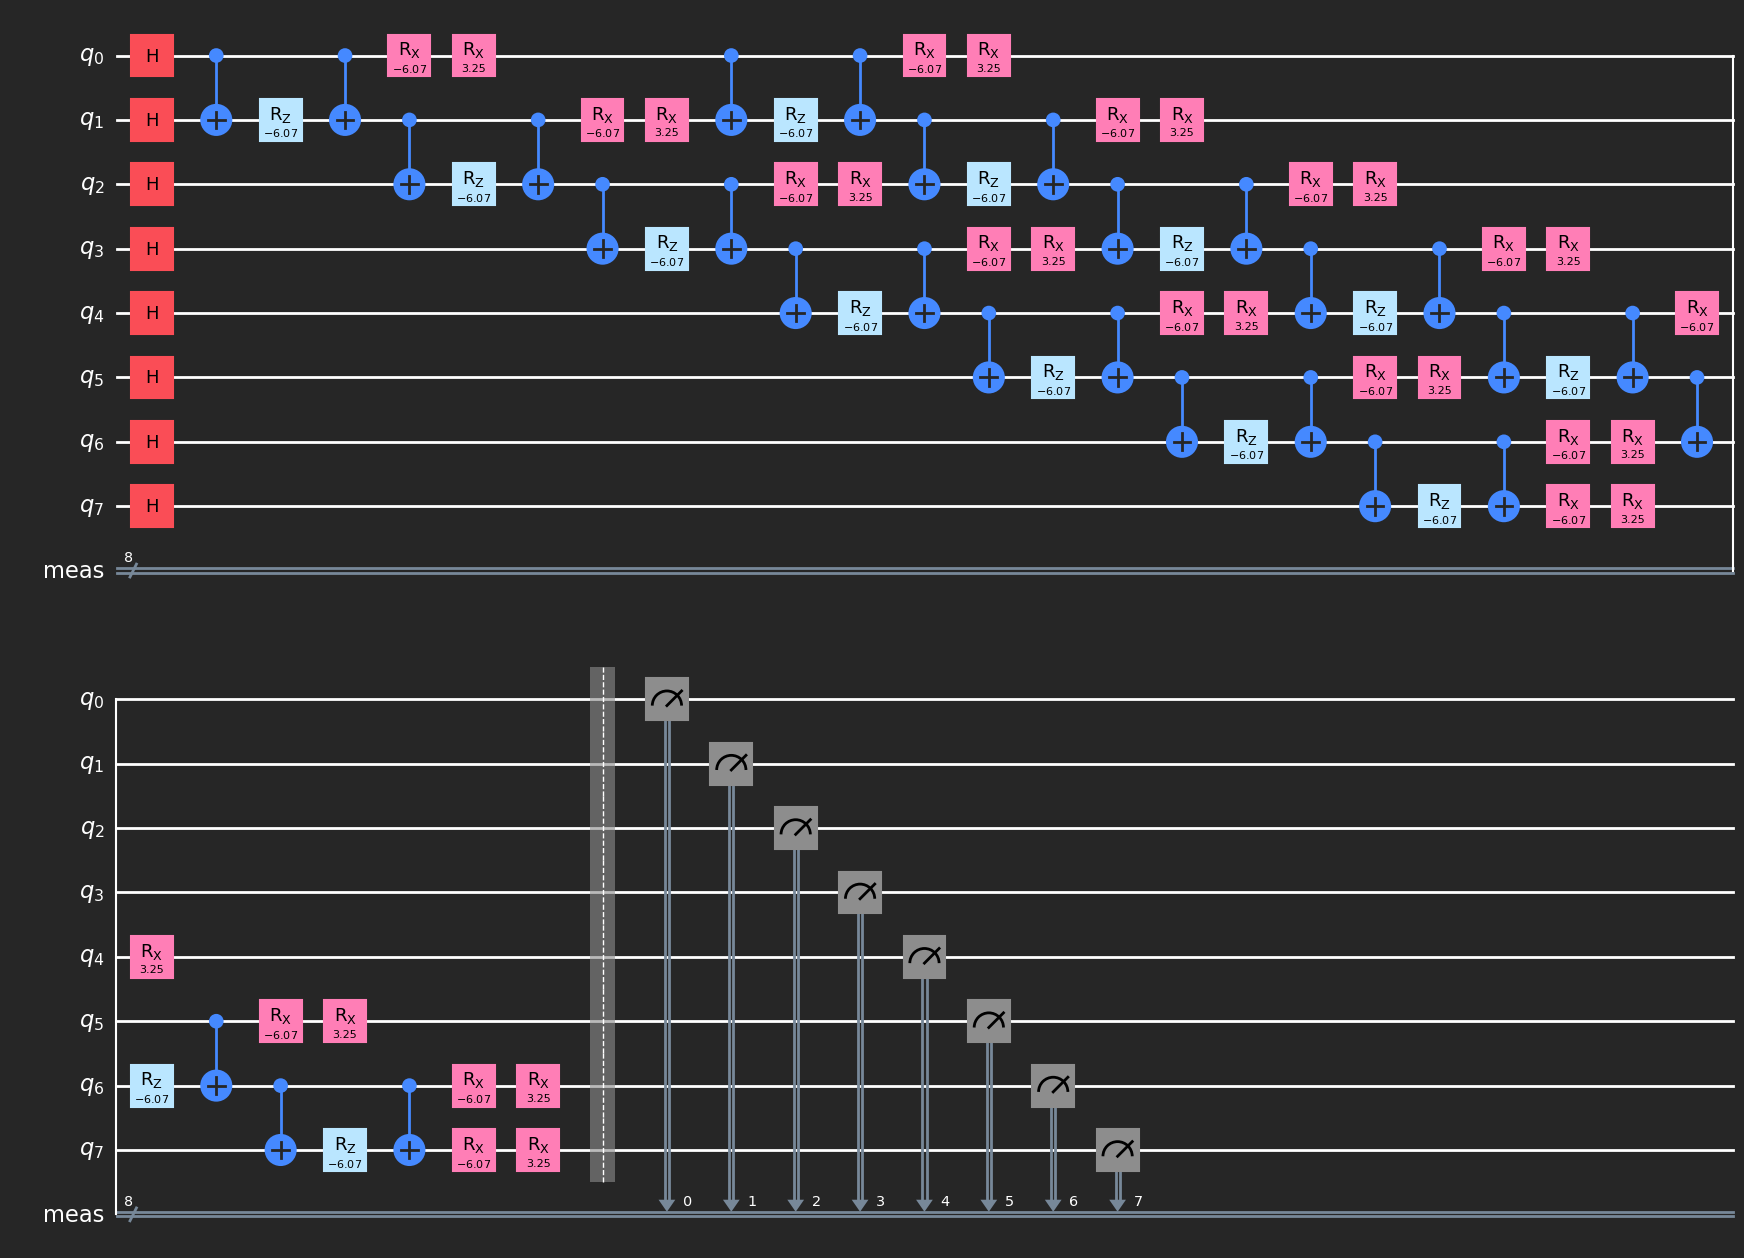

In [92]:
ising_optimized = QuantumCircuit(n_qubits)
ising_optimized.h(range(n_qubits))

for _ in range(optimal_layers):
    ising_optimized.compose(
        
        qaoa_layer(optimal_beta, optimal_gamma, H_ising, n_qubits),
        inplace = True
    
    )

psi_optimized = Statevector.from_instruction(ising_optimized)
ev_optimized = psi_optimized.expectation_value(H_ising).real

ising_optimized.measure_all()
draw_circuit(ising_optimized)

Do note that results may vary from just a few codeblocks earlier. We *are* running on real hardware after all, and noise and decoherence can significantly affect the results. Feel free to run multiple times to see how consistent the results are.

In [93]:
service = QiskitRuntimeService()
backend = service.least_busy(operational = True, simulator = False)

print(backend, backend.num_qubits)

qiskit_runtime_service._resolve_cloud_instances:WARNING:2025-12-18 04:14:02,337: Default instance not set. Searching all available instances.


<IBMBackend('ibm_fez')> 156


In [106]:
ising_optimized = transpile(ising_optimized, backend = backend, optimization_level = 3)
sampler = SamplerV2(mode = backend)

job = sampler.run([ising_optimized], shots = 2 ** 14)
result = job.result()
counts = result[0].data.meas.get_counts()

Like before, I recommend against plotting the distribution to prevent an aneurysm :)

In [107]:
best_string = max(counts, key = counts.get)

def classical_energy(bitstring, hamiltonian):
    energy = 0.0
    n_qubits = len(bitstring)
    
    for pauli, coeff in zip(hamiltonian.paulis.to_labels(), hamiltonian.coeffs):
        term_value = 1.0
        
        for i, p in enumerate(pauli):
            if p == "Z":
                z_value = 1 if bitstring[n_qubits - i - 1] == '0' else -1
                term_value *= z_value
        
        energy += coeff.real * term_value
    
    return energy

measured_energy = classical_energy(best_string, H_ising)
print(f"Most frequent bitstring: {best_string} with energy {measured_energy} units and probability: {counts[best_string] / sum(counts.values()):.4f}")

Most frequent bitstring: 11111111 with energy -15.0 units and probability: 0.0236


This is the actual QAOA output we expect from real hardware. The bitstring with the highest count corresponds to the optimal solution found by the algorithm, which in this case is... whatever you get. Remember, a 0 bit means spin up (+1) and a 1 bit means spin down (-1). You can interpret the results accordingly based on the problem you're solving.

***

Congratulations on completing this monster of a notebook. I know you probably would ask me to split this into multiple smaller notebooks, but I wanted to keep everything in one place for easier reference as everything here is interconnected. Feel free to revisit any section as needed, and happy coding!